# EDA

Для проекта будем использовать датасет [neoyipeng/modernfinbert-training-v2](https://huggingface.co/datasets/neoyipeng/modernfinbert-training-v2). В нём собраны новости, твиты, аналитические отчёты и стенограммы.

OpenAI Codex был использован для подготовки ноутбука.

In [2]:
%pip install -q pandas pyarrow matplotlib seaborn wordcloud nltk datasets scikit-learn

import pandas as pd
from datasets import load_dataset

splits = load_dataset("neoyipeng/modernfinbert-training-v2")
pd.set_option("display.max_colwidth", 160)
splits["train"].to_pandas().head()

,text,label,source,source_domain,label_confidence,entity,entity_sentiment
0,$TWTR #twitter,NEUTRAL,timkoornstra_tweets,social_media,human_aggregated,Twitter Inc.,NEUTRAL
1,"Yeah, I'd be happy to. So first, just on the share repurchase, I will just echo what you said, don't read anything into that. I would say for this year, we ...",NEUTRAL,subjectiveqa,earnings_calls,human,MARKET,NEUTRAL
2,"You know, Alexia, it’s a little early for us to comment on the cost side for next year. We are literally just beginning to look at the budgets that are bubb...",POSITIVE,subjectiveqa,earnings_calls,human,MARKET,POSITIVE
3,The study was conducted in 229 moderate to severe psoriasis patients.,NEUTRAL,financemteb_finsent,analyst_reports,human,NONE,NEUTRAL
4,"While electronics are certainly cyclical, BNT is exposed to a growth segment that is highly dependent on new product introductions.",NEGATIVE,financemteb_finsent,analyst_reports,human,NONE,NEGATIVE


| Столбец | Содержание |
|---|---|
| `text` | Исходный текст |
| `label` | Тональность всего текста: `NEGATIVE`, `NEUTRAL`, `POSITIVE` |
| `source` | Датасет-источник |
| `source_domain` | Тип текста |
| `label_confidence` | Способ получения `label` |
| `entity` | Объект оценки: например, компания Apple, тикер, индекс или сектор |
| `entity_sentiment` | Тональность по отношению к этому объекту |

Берём `text` как вход и `label` как целевую метку.

In [3]:
parts = []
for name in ["train", "validation", "test"]:
    table = splits[name].to_pandas()
    parts.append(table.assign(split=name))
df = pd.concat(parts, ignore_index=True)
train = df.loc[df["split"].eq("train")].reset_index(drop=True).copy()
print("Всего строк:", len(df))
df["split"].value_counts().reset_index(name="Строк")

Всего строк: 43247


,split,Строк
0,train,34597
1,validation,4325
2,test,4325


43 247 текстов: 34 597 train, по 4 325 validation и test.

Пропуски, допустимые метки и дубли проверяем на всём наборе. Распределения и примеры для анализа признаков - только на train.

## 1. Пропуски и метки

In [4]:
LABELS = ["NEGATIVE", "NEUTRAL", "POSITIVE"]

empty_counts = {}
for column in df.columns:
    empty = df[column].eq("") | df[column].str.isspace()
    empty_counts[column] = empty.sum()

display(pd.DataFrame({
    "Пропуски": df.isna().sum(),
    "Пустые строки": pd.Series(empty_counts),
}))
print("Неизвестных label:", (~df["label"].isin(LABELS)).sum())
print("Неизвестных entity_sentiment:", (~df["entity_sentiment"].isin(LABELS)).sum())

,Пропуски,Пустые строки
text,0,0
label,0,0
source,0,0
source_domain,0,0
label_confidence,0,0
entity,0,0
entity_sentiment,0,0
split,0,0


Неизвестных label: 0
Неизвестных entity_sentiment: 0


Пропусков, пустых строк и неизвестных меток нет.

In [5]:
display(train["entity"].value_counts().head(8).reset_index(name="Текстов"))

different_target = train["label"] != train["entity_sentiment"]
print("label отличается от entity_sentiment в train:", different_target.sum())
display(train.loc[different_target, ["text", "label", "entity", "entity_sentiment"]].sample(3, random_state=42))

,entity,Текстов
0,NONE,14108
1,MARKET,8123
2,NASDAQ,316
3,88 Energy Ltd.,309
4,$EEENF,296
5,Apple Inc.,287
6,Tesla Inc.,269
7,Microsoft Corp.,165


label отличается от entity_sentiment в train: 1656


,text,label,entity,entity_sentiment
30461,FIO im in ONG for 24 - 28 untill March 2013,POSITIVE,MARKET,NEUTRAL
8281,$AMD October is a volatile month. BUY exceptional business when you see Red days. Buying during chaos &amp; Volatility have made riches. Long term bullish o...,POSITIVE,MARKET,NEGATIVE
16792,$AAPL keeps on pushing making a new ATH yet again. It's closing in on the $3T mark. Do you think it gets there by the end of the year?,POSITIVE,MARKET,NEUTRAL


В train `NONE` (объект не указан) встречается в 14 108 строках (40,8%), `MARKET` (рынок в целом) - в 8 123 (23,5%). В 1 656 строках (4,8%) `label` и `entity_sentiment` различаются.

## 2. Повторяющиеся и похожие тексты

In [6]:
original_columns = splits["train"].column_names
print("Полных повторов:", df.duplicated(original_columns).sum())
print("Повторных текстов:", df.duplicated("text").sum())
labels_per_text = df.groupby("text")["label"].nunique()
print("Одинаковых текстов с разными label:", labels_per_text.gt(1).sum())

overlaps = []
for left, right in [("train", "validation"), ("train", "test"), ("validation", "test")]:
    shared = set(splits[left]["text"]) & set(splits[right]["text"])
    overlaps.append([left, right, len(shared)])
display(pd.DataFrame(overlaps, columns=["Split 1", "Split 2", "Общих текстов"]))

Полных повторов: 0
Повторных текстов: 0
Одинаковых текстов с разными label: 0


,Split 1,Split 2,Общих текстов
0,train,validation,0
1,train,test,0
2,validation,test,0


Точных повторов строк и текстов нет, в том числе между train, validation и test.

### После нормализации

Приводим Unicode и регистр к единому виду, декодируем HTML-коды, убираем знаки, эмодзи и лишние пробелы.

In [7]:
import html

normalized_text = (
    df["text"].map(html.unescape)
    .str.normalize("NFKC")
    .str.casefold()
    .apply(lambda text: "".join(
        char if char.isalnum() or char == "_" else " " for char in text
    ))
    .str.split().str.join(" ")
)
normalized_groups = df.groupby(normalized_text).agg(
    rows=("text", "size"), labels=("label", "nunique"), splits=("split", "nunique")
)
print("Повторов после нормализации:", normalized_text.duplicated().sum())
print("Групп повторов:", normalized_groups["rows"].gt(1).sum())
print("Строк в этих группах:", normalized_text.duplicated(keep=False).sum())
print("Групп с разными label:", normalized_groups["labels"].gt(1).sum())

normalized_overlaps = []
for left, right in [("train", "validation"), ("train", "test"), ("validation", "test")]:
    left_texts = set(normalized_text[df["split"].eq(left)])
    right_texts = set(normalized_text[df["split"].eq(right)])
    normalized_overlaps.append([left, right, len(left_texts & right_texts)])
display(pd.DataFrame(normalized_overlaps, columns=["Split 1", "Split 2", "Общих нормализованных текстов"]))

Повторов после нормализации: 7
Групп повторов: 4
Строк в этих группах: 11
Групп с разными label: 0


,Split 1,Split 2,Общих нормализованных текстов
0,train,validation,0
1,train,test,1
2,validation,test,0


После нормализации найдено 7 повторов: 11 строк в 4 группах. Расхождений `label` нет. В одной группе есть тексты из train и test.

In [8]:
duplicate_examples = df.loc[normalized_text.duplicated(keep=False), ["text", "label", "split"]].copy()
duplicate_examples["Нормализованный текст"] = normalized_text.loc[duplicate_examples.index]
duplicate_examples.sort_values(["Нормализованный текст", "split"])

,text,label,split,Нормализованный текст
19014,@AlexDelarge6553 $eeenf to 🚀🌖🍀🛢💥👌🏼,POSITIVE,train,alexdelarge6553 eeenf to
21041,@AlexDelarge6553 $eeenf to 🚀🍀💥💸,POSITIVE,train,alexdelarge6553 eeenf to
42835,$EEENF 🚀🚀🚀🚀🚀🚀,POSITIVE,test,eeenf
2953,$EEENF ⛽️⛽️🚀🚀,POSITIVE,train,eeenf
6796,$EEENF 😭🙏🚀,POSITIVE,train,eeenf
10536,$EEENF 🔥🔥🔥🔥💪🏻,POSITIVE,train,eeenf
25640,$EEENF 🚀🚀🚀,POSITIVE,train,eeenf
14669,"$T *All that you need to know., Shorts haven't covered a single share..,,,",POSITIVE,train,t all that you need to know shorts haven t covered a single share
19245,$T All that you need to know. Shorts haven't covered a single share,POSITIVE,train,t all that you need to know shorts haven t covered a single share
12920,"$TSLA long call scalping,,,.",POSITIVE,train,tsla long call scalping


В train и test есть твиты `$EEENF`, которые отличаются эмодзи.

### Почти одинаковые тексты

TF-IDF символьных 3-5-грамм и косинусная близость >= 0,95. Сравниваем тексты из train, validation и test. У каждой пары проверяем `label`.

In [9]:
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import linear_kernel

SIMILARITY_THRESHOLD = 0.95
BATCH_SIZE = 128

near_text = (
    df["text"].map(html.unescape)
    .str.normalize("NFKC").str.casefold()
    .str.split().str.join(" ")
)
vectorizer = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5),
                             sublinear_tf=True, norm="l2", dtype=np.float32)
text_vectors = vectorizer.fit_transform(near_text)

near_parts = []
for start in range(0, len(df), BATCH_SIZE):
    # Для нормированных TF-IDF скалярное произведение равно косинусу.
    similarities = linear_kernel(text_vectors[start:start + BATCH_SIZE], text_vectors)
    left, right = np.where(similarities >= SIMILARITY_THRESHOLD)
    scores = similarities[left, right]
    left = left + start
    keep = left < right  # Без сравнения с собой и повторного учёта пары.
    near_parts.append(pd.DataFrame({
        "id_left": left[keep], "id_right": right[keep], "cosine": scores[keep],
    }))

near_pairs = pd.concat(near_parts, ignore_index=True).sort_values("cosine", ascending=False)
for side in ["left", "right"]:
    for column in ["text", "label", "split"]:
        near_pairs[f"{column}_{side}"] = df.loc[near_pairs[f"id_{side}"], column].to_numpy()
near_pairs["same_label"] = near_pairs["label_left"].eq(near_pairs["label_right"])
near_pairs["same_split"] = near_pairs["split_left"].eq(near_pairs["split_right"])
near_pairs = near_pairs.reset_index(drop=True)

print("Похожих пар:", len(near_pairs))
print("С одинаковыми label:", near_pairs["same_label"].sum())
print("С разными label:", (~near_pairs["same_label"]).sum())
print("Между разными split:", (~near_pairs["same_split"]).sum())
display(near_pairs.groupby(["split_left", "split_right"]).agg(
    Пар=("same_label", "size"),
    Разные_метки=("same_label", lambda values: (~values).sum()),
))

Похожих пар: 5
С одинаковыми label: 3
С разными label: 2
Между разными split: 1


Пар  Разные_метки
split_left split_right                   
train      test           1             0
           train          4             2

Найдено 5 пар. В 3 парах метки совпадают, в 2 различаются. В одной паре один текст находится в train, другой в test. У них одинаковые метки.

In [10]:
columns = ["cosine", "text_left", "label_left", "split_left",
           "text_right", "label_right", "split_right", "same_label"]
with pd.option_context("display.max_colwidth", None):
    display(near_pairs[columns].round({"cosine": 3}))

,cosine,text_left,label_left,split_left,text_right,label_right,split_right,same_label
0,0.995,has turned into complete garbage. \n,NEGATIVE,train,it has turned into complete garbage. \n,NEGATIVE,train,True
1,0.979,Oil trades at 3-month high https://t.co/6F8tuUZLyb,POSITIVE,train,Oil trades at 3-month low https://t.co/6F8tuUZLyb,NEGATIVE,train,False
2,0.979,Consumer Inflation Eases To 6.58% In February\nhttps://t.co/LOjPNFJ30r,POSITIVE,train,Consumer Inflation At 6.58% In February\nhttps://t.co/LOjPNFJ30r,POSITIVE,test,True
3,0.968,"Bloomberg Daybreak: Feb. 7, 2020 - Hour 1 (Radio)",NEUTRAL,train,"Bloomberg Daybreak: Feb. 6, 2020 - Hour 1 (Radio)",NEUTRAL,train,True
4,0.953,@AlexDelarge6553 $TTCM,NEUTRAL,train,@AlexDelarge6553 $TTCM great day,POSITIVE,train,False


В двух парах с разными метками меняется смысл: `high` заменён на `low`, в другом тексте добавлено `great day`.

## 3. Классы и источники - train

In [11]:
counts = train["label"].value_counts().reindex(LABELS)
pd.DataFrame({"Текстов": counts, "Доля, %": counts / len(train) * 100}).round(1).rename_axis("Тональность").reset_index()

,Тональность,Текстов,"Доля, %"
0,NEGATIVE,9681,28.0
1,NEUTRAL,13175,38.1
2,POSITIVE,11741,33.9


В train `NEUTRAL` - 38,1%, `POSITIVE` - 33,9%, `NEGATIVE` - 28,0%.

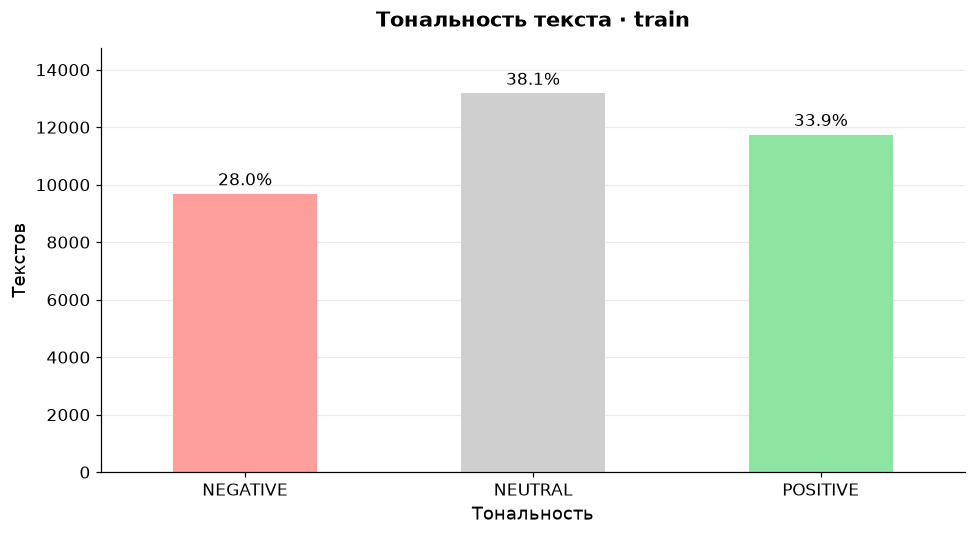

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

PALETTE = sns.color_palette("pastel", 8)
LABEL_COLORS = {"NEGATIVE": PALETTE[3], "NEUTRAL": PALETTE[7], "POSITIVE": PALETTE[2]}

plt.rcParams.update({
    "figure.figsize": (9, 5),
    "figure.dpi": 110,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.alpha": 0.25,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.titlepad": 14,
    "axes.labelsize": 12,
    "font.size": 11,
    "legend.frameon": False,
})

fig, ax = plt.subplots()
counts.plot.bar(rot=0, color=[LABEL_COLORS[label] for label in LABELS], ax=ax)
ax.set(title="Тональность текста · train", xlabel="Тональность", ylabel="Текстов")
ax.bar_label(ax.containers[0], labels=[f"{n / len(train):.1%}" for n in counts], padding=3)
ax.set_ylim(0, counts.max() * 1.12)
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

Дисбаланс умеренный. Для сравнения моделей подойдёт macro-F1 с precision/recall по классам. Качество на менее представленных стенограммах проверим отдельно.

,source_domain,Текстов
0,social_media,12000
1,financial_news,12000
2,analyst_reports,7943
3,earnings_calls,2654


,source,NEGATIVE,NEUTRAL,POSITIVE
0,aiera_transcripts,53,341,164
1,financemteb_finsent,1460,3636,2847
2,nosible,4000,4000,4000
3,subjectiveqa,168,1198,730
4,timkoornstra_tweets,4000,4000,4000


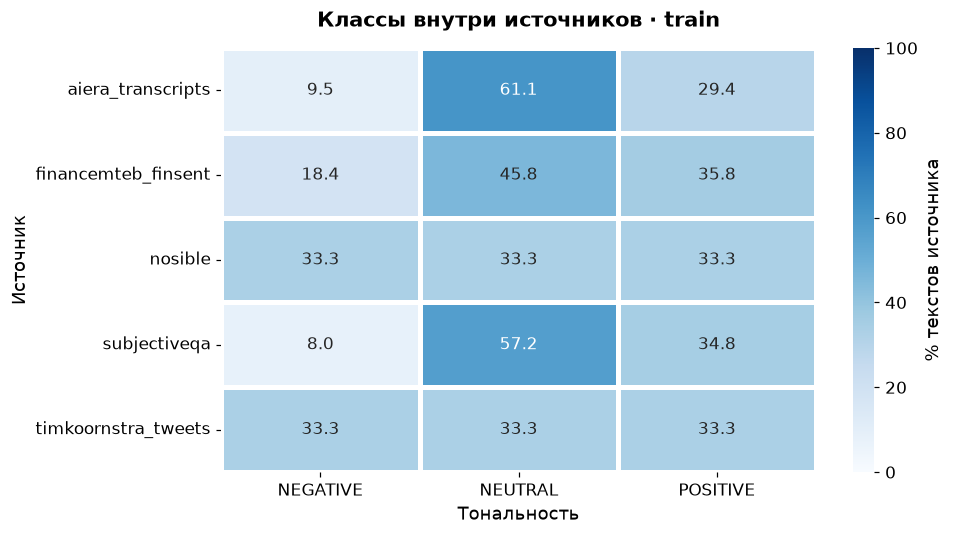

In [13]:
display(train["source_domain"].value_counts().reset_index(name="Текстов"))

source_labels = pd.crosstab(train["source"], train["label"]).reindex(columns=LABELS)
display(source_labels.rename_axis(None, axis=1).reset_index())

source_shares = source_labels.div(source_labels.sum(axis=1), axis=0) * 100
fig, ax = plt.subplots(figsize=(9, 5))
sns.heatmap(source_shares, annot=True, fmt=".1f", cmap="Blues", vmin=0, vmax=100,
            linewidths=2, ax=ax, cbar_kws={"label": "% текстов источника"})
ax.set(xlabel="Тональность", ylabel="Источник", title="Классы внутри источников · train")
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
ax.grid(False)
plt.tight_layout()
plt.show()

Новости `nosible` и твиты составляют 69,4% обучающей выборки (24 000 строк). В каждом из этих источников по 4 000 текстов каждого класса. В стенограммах преобладает `NEUTRAL`: 57,2% у `subjectiveqa`, 61,1% у `aiera_transcripts`.

In [14]:
pd.crosstab(train["source"], train["label_confidence"]).rename_axis(None, axis=1).reset_index()

,source,human,human_aggregated,llm_consensus
0,aiera_transcripts,558,0,0
1,financemteb_finsent,7943,0,0
2,nosible,0,0,12000
3,subjectiveqa,2096,0,0
4,timkoornstra_tweets,0,12000,0


`label_confidence` обозначает происхождение `label` по карточке датасета. Числа ниже приведены для train.

- `llm_consensus` - метки новостей NOSIBLE получены согласованием ответов нескольких языковых моделей, 12 000 текстов.
- `human_aggregated` - метки из девяти наборов твитов, объединённых в [TimKoornstra](https://huggingface.co/datasets/TimKoornstra/financial-tweets-sentiment) с единой схемой классов, 12 000 текстов.
- `human` - метки из разметки FinSent, SubjECTive-QA и Aiera, где тональность оценивали люди, 10 597 текстов.

`entity` и `entity_sentiment` добавлены агентами Claude Code.

## 4. Длина

Слова считаются разделением по пробельным символам. Символы включают пробелы и пунктуацию.

In [15]:
lengths = pd.DataFrame()
lengths["Слова"] = train["text"].str.split().str.len()
lengths["Символы"] = train["text"].str.len()
lengths.describe(percentiles=[0.25, 0.5, 0.75, 0.95, 0.99]).round(2)

,Слова,Символы
count,34597.00,34597.00
mean,50.99,317.14
std,58.04,346.19
min,1.00,10.00
25%,14.00,89.00
50%,26.00,158.00
75%,75.00,469.00
95%,152.00,953.00
99%,212.04,1187.08
max,1973.00,10466.00


Средняя длина - 50,99 слова / 317,14 символа, медиана - 26 / 158. Длина варьируется от 1 до 1 973 слов и от 10 до 10 466 символов. 99-й перцентиль - около 212 слов.

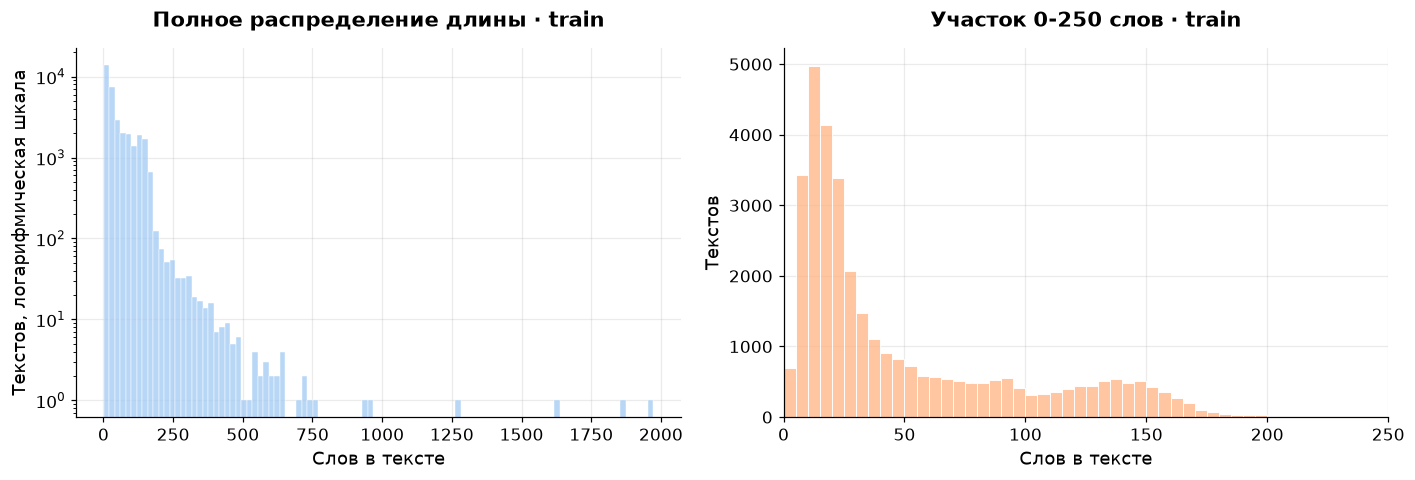

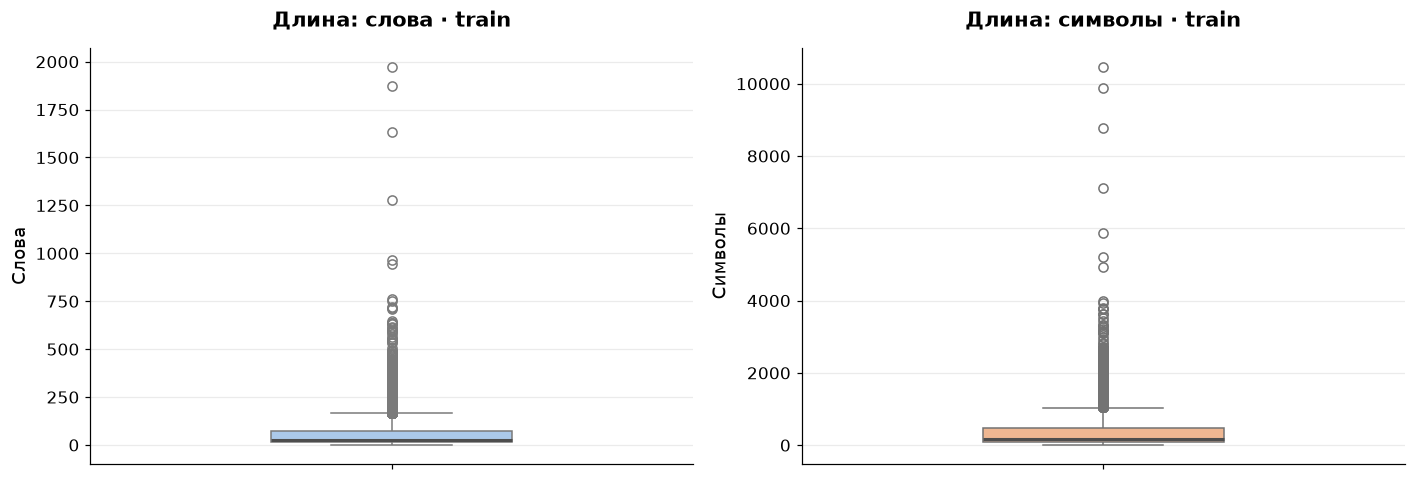

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(data=lengths, x="Слова", bins=100, color=PALETTE[0], edgecolor="white", ax=axes[0])
axes[0].set(yscale="log", xlabel="Слов в тексте", ylabel="Текстов, логарифмическая шкала",
            title="Полное распределение длины · train")
sns.histplot(data=lengths.loc[lengths["Слова"].le(250)], x="Слова", bins=range(0, 251, 5),
             color=PALETTE[1], edgecolor="white", ax=axes[1])
axes[1].set(xlim=(0, 250), xlabel="Слов в тексте", ylabel="Текстов",
            title="Участок 0-250 слов · train")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, column, color in zip(axes, ["Слова", "Символы"], PALETTE[:2]):
    sns.boxplot(data=lengths, y=column, color=color, width=0.4,
                medianprops={"color": "0.3", "linewidth": 2}, ax=ax)
    ax.set(title=f"Длина: {column.lower()} · train", ylabel=column)
    ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

У распределения длинный правый хвост: большинство текстов короткие, но встречаются тексты на сотни и тысячи слов.

In [17]:
lengths.groupby(train["source"]).agg(["mean", "median", "max"]).round(1)

Слова              Символы              
                      mean median   max    mean median    max
source                                                       
aiera_transcripts     41.8   23.0   248   243.3  132.0   1326
financemteb_finsent   22.3   20.0   106   139.4  126.0    681
nosible               92.7   89.0   762   591.5  565.0   5867
subjectiveqa         128.2   96.0  1973   704.5  523.5  10466
timkoornstra_tweets   15.3   13.0   636    96.2   84.0   3507

Медиана твита - 13 слов, новости `nosible` - 89, ответа `subjectiveqa` - 96. Длинный правый хвост создают прежде всего стенограммы.

In [18]:
q1, q3 = lengths["Слова"].quantile([0.25, 0.75])
iqr = q3 - q1
outliers = (lengths["Слова"] < q1 - 1.5 * iqr) | (lengths["Слова"] > q3 + 1.5 * iqr)
print("Границы 1,5 IQR:", q1 - 1.5 * iqr, q3 + 1.5 * iqr)
print("Строк за границами:", outliers.sum())
display(train.loc[outliers, "source"].value_counts().to_frame("Текстов"))

shortest = lengths["Слова"].idxmin()
longest = lengths["Слова"].idxmax()
extremes = train.loc[[shortest, longest], ["text", "label", "source"]].copy()
extremes["Слова"] = lengths.loc[extremes.index, "Слова"]
with pd.option_context("display.max_colwidth", 500):
    display(extremes)

url_only = train["text"].apply(
    lambda text: text.startswith(("http://", "https://"))
    and bool(text.partition("://")[2])
    and not any(char.isspace() for char in text)
)
print("Текстов только из ссылки:", url_only.sum())
display(train.loc[url_only, ["text", "label", "source"]])

Границы 1,5 IQR: -77.5 166.5
Строк за границами: 802


,Текстов
source,
subjectiveqa,558
nosible,224
aiera_transcripts,13
timkoornstra_tweets,7


,text,label,source,Слова
436,https://t.co/oJxNPEUpWq,NEUTRAL,timkoornstra_tweets,1
11903,"Yes. Well, I think it's going to be a meaningful brand enhancer. And I think if - it's funny I - if you would ask me five or seven years ago, we started work upon this, I would have told you it's going to be a meaningful brand enhancer. Now, I look back, and I go, that wasn't even any good at all. We were working five, seven years ago because we keep - tend to keep making things better. And that's the great thing about kind of only having a vision about something versus kind of start working...",POSITIVE,subjectiveqa,1973


Текстов только из ссылки: 2


,text,label,source
436,https://t.co/oJxNPEUpWq,NEUTRAL,timkoornstra_tweets
2662,https://t.co/575AH1YRkF,NEUTRAL,timkoornstra_tweets


За границей IQR - 802 текста, из них 558 относятся к `subjectiveqa`. Самый длинный текст - развёрнутый ответ во время звонка с инвесторами. Два коротких текста содержат только ссылку.

In [19]:
cut_stats = []
for limit in [128, 256, 512]:
    lost = (lengths["Слова"] - limit).clip(lower=0)
    cut_stats.append([limit, lost.gt(0).sum(), lost.sum() / lengths["Слова"].sum() * 100])
pd.DataFrame(cut_stats, columns=["Лимит слов", "Затронуто текстов", "Потеря слов, %"]).round(2)

,Лимит слов,Затронуто текстов,"Потеря слов, %"
0,128,4050,8.68
1,256,230,1.81
2,512,29,0.46


Лимит 128 слов затронул бы 4 050 текстов и убрал 8,7% слов. Лимит 256 слов - 230 текстов и 1,8% слов. Для TF-IDF тексты можно сохранить целиком. Обрезка особенно затронет стенограммы.

## 5. Символы и технические особенности

In [20]:
has_non_ascii = train["text"].apply(lambda text: not text.isascii())
non_ascii_chars = train["text"].apply(
    lambda text: [char for char in text if not char.isascii()]
)
has_non_ascii_letters = non_ascii_chars.apply(
    lambda chars: any(char.isalpha() for char in chars)
)

display(pd.DataFrame({
    "Текстов": [has_non_ascii.sum(), has_non_ascii_letters.sum()],
    "Доля, %": [has_non_ascii.mean() * 100, has_non_ascii_letters.mean() * 100],
}, index=["Есть символы вне ASCII", "Есть буквы вне ASCII"]).round(2))

non_ascii_counts = non_ascii_chars.explode().value_counts().head(10)
pd.DataFrame({
    "Символ": [repr(char) for char in non_ascii_counts.index],
    "Код": [f"U+{ord(char):04X}" for char in non_ascii_counts.index],
    "Вхождений": non_ascii_counts.to_numpy(),
})

,Текстов,"Доля, %"
Есть символы вне ASCII,6406,18.52
Есть буквы вне ASCII,474,1.37


,Символ,Код,Вхождений
0,'’',U+2019,3142
1,'…',U+2026,1691
2,'–',U+2013,1464
3,'🚀',U+1F680,1067
4,'🔥',U+1F525,973
5,'—',U+2014,896
6,'€',U+20AC,318
7,'£',U+00A3,307
8,'┬',U+252C,298
9,'®',U+00AE,256


Не-ASCII символы есть в 6 406 текстах train (18,5%). Буквы вне ASCII встречаются в 474 текстах (1,4%). Среди частых символов есть типографская пунктуация и эмодзи.

In [21]:
import html

checks = pd.DataFrame()
checks["Угловые конструкции"] = train["text"].str.contains(r"</?[A-Za-z][^>]*>")
checks["HTML-коды"] = train["text"].apply(html.unescape).ne(train["text"])
checks["URL"] = train["text"].apply(
    lambda text: any(part in text for part in ("http://", "https://", "www."))
)
checks["Цифры"] = train["text"].apply(
    lambda text: any(char.isdecimal() for char in text)
)
checks["Проценты"] = train["text"].str.contains("%", regex=False)
checks["Вопросы"] = train["text"].str.contains("?", regex=False)
checks["Восклицания"] = train["text"].str.contains("!", regex=False)

import string

checks["Пунктуация"] = train["text"].apply(
    lambda text: any(char in string.punctuation for char in text)
)
display(pd.DataFrame({"Текстов": checks.sum(), "Доля, %": checks.mean() * 100}).round(2))

display(train.loc[checks["Угловые конструкции"], ["text", "source"]])

,Текстов,"Доля, %"
Угловые конструкции,2,0.01
HTML-коды,290,0.84
URL,3539,10.23
Цифры,21782,62.96
Проценты,5115,14.78
Вопросы,1387,4.01
Восклицания,984,2.84
Пунктуация,33606,97.14


,text,source
2068,$TSLA <STUDY the CHARTS> Pullback_Time https://t.co/ZMDG0fb3I7,timkoornstra_tweets
25125,The second item of business is a vote to approve an amendment to our certificate of incorporation to effect a reverse stock split at a ratio in the range of...,aiera_transcripts


URL есть в 10,2% текстов train, пунктуация - в 97,1%, цифры - в 63,0%. HTML-коды найдены в 290 строках. Два совпадения в угловых скобках - `<STUDY the CHARTS>` и служебный токен `<unk>`.

HTML-коды и ссылки обработаем отдельно. Числа, проценты и тикеры сохраним.

## 6. Длина и тональность - train

In [22]:
length_by_label = lengths.assign(label=train["label"])
length_summary = length_by_label.groupby("label")["Слова"].agg(
    Текстов="size", Среднее="mean", Медиана="median",
    Q25=lambda x: x.quantile(0.25), Q75=lambda x: x.quantile(0.75)
).reindex(LABELS)
length_summary.round(2)

,Текстов,Среднее,Медиана,Q25,Q75
label,,,,,
NEGATIVE,9681,51.92,29.0,14.0,81.0
NEUTRAL,13175,46.45,23.0,13.0,63.0
POSITIVE,11741,55.33,27.0,15.0,83.0


Нейтральные тексты короче: медиана 23 слова против 29 у `NEGATIVE` и 27 у `POSITIVE`.

label,NEGATIVE,NEUTRAL,POSITIVE,Текстов
Слова,,,,
1-10,29.3,39.4,31.3,5204
11-25,25.3,41.8,33.0,11916
26-50,28.4,37.4,34.2,6018
51-100,30.6,36.2,33.2,5293
101-200,30.8,32.0,37.1,5770
201+,8.3,34.3,57.3,396


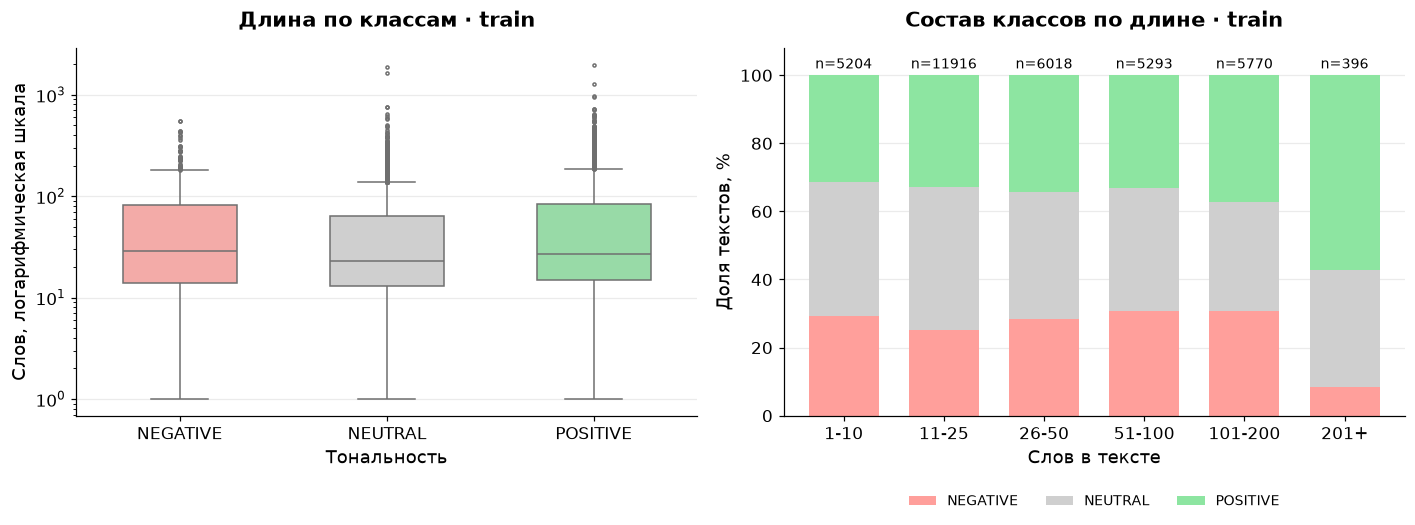

In [23]:
LENGTH_BINS = [0, 10, 25, 50, 100, 200, float("inf")]
LENGTH_LABELS = ["1-10", "11-25", "26-50", "51-100", "101-200", "201+"]
length_group = pd.cut(lengths["Слова"], bins=LENGTH_BINS, labels=LENGTH_LABELS)
length_counts = pd.crosstab(length_group, train["label"]).reindex(columns=LABELS)
length_shares = length_counts.div(length_counts.sum(axis=1), axis=0) * 100
display(length_shares.assign(Текстов=length_counts.sum(axis=1)).round(1))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.boxplot(data=length_by_label, x="label", y="Слова", hue="label",
            order=LABELS, hue_order=LABELS, palette=LABEL_COLORS, legend=False,
            width=0.55, fliersize=2, ax=axes[0])
axes[0].set(yscale="log", xlabel="Тональность", ylabel="Слов, логарифмическая шкала",
            title="Длина по классам · train")
axes[0].grid(axis="x", visible=False)

length_shares.plot.bar(stacked=True, color=[LABEL_COLORS[label] for label in LABELS],
                       rot=0, width=0.7, ax=axes[1])
axes[1].set(xlabel="Слов в тексте", ylabel="Доля текстов, %", ylim=(0, 108),
            title="Состав классов по длине · train")
axes[1].legend(title=None, loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=3,
                fontsize=9)
axes[1].grid(axis="x", visible=False)
for i, n in enumerate(length_counts.sum(axis=1)):
    axes[1].text(i, 102, f"n={n}", ha="center", fontsize=9)
plt.tight_layout()
plt.show()

Диапазоны длин сильно перекрываются. Среди 396 текстов длиннее 200 слов 57,3% положительных. Длину можно проверить как дополнительный признак к TF-IDF.

In [24]:
source_length_medians = train.assign(Слова=lengths["Слова"]).pivot_table(
    index="source", columns="label", values="Слова", aggfunc="median"
).reindex(columns=LABELS)
source_length_medians.rename_axis("Источник").round(1)

label,NEGATIVE,NEUTRAL,POSITIVE
Источник,,,
aiera_transcripts,45.0,19.0,33.5
financemteb_finsent,22.0,19.0,22.0
nosible,91.0,82.0,95.0
subjectiveqa,97.0,76.0,139.5
timkoornstra_tweets,13.0,12.0,13.0


Нейтральные тексты короче по медиане внутри каждого источника.

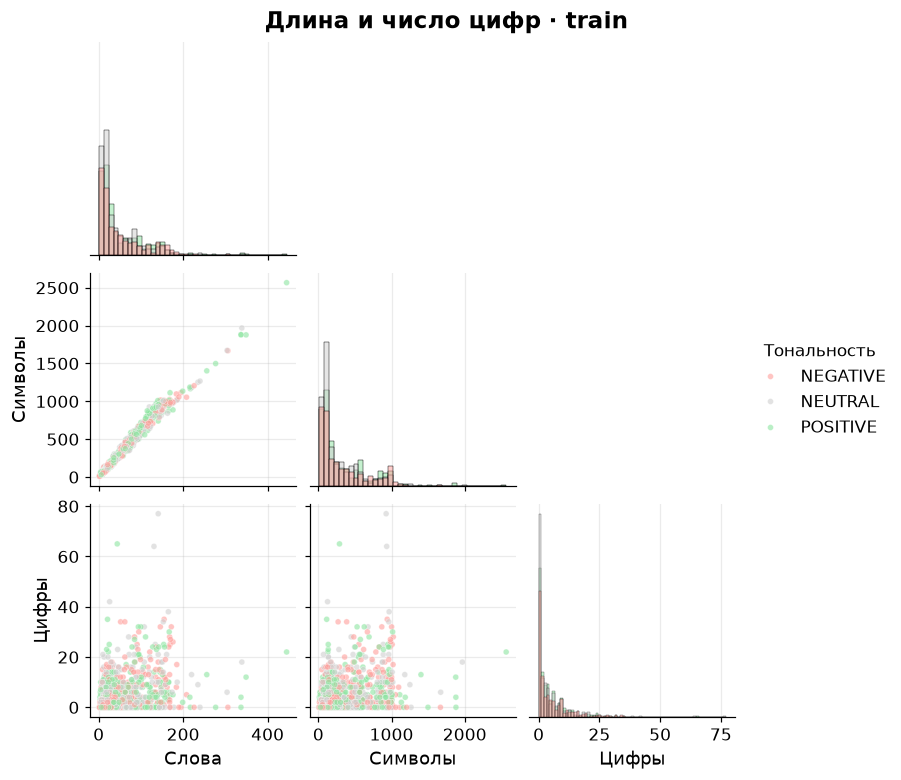

In [25]:
features = lengths.copy()
features["Цифры"] = train["text"].apply(
    lambda text: sum(char.isdecimal() for char in text)
)

plot_data = features.sample(1200, random_state=42).copy()
plot_data["Тональность"] = train.loc[plot_data.index, "label"]
pair = sns.pairplot(plot_data, hue="Тональность", hue_order=LABELS, palette=LABEL_COLORS,
                    corner=True, diag_kind="hist", height=2.3,
                    plot_kws={"alpha": 0.6, "s": 15})
pair.figure.suptitle("Длина и число цифр · train", y=1.02, fontsize=15, fontweight="bold")
plt.show()

На парных графиках классы перекрываются.

## 7. Частые слова

Здесь слова считаются как написаны: между пробелами, вместе с числами и знаками.

Всего слов: 1764183
Разных написаний: 148822


text
the     76330
to      47094
and     44878
of      44536
in      33947
a       32080
that    17196
for     16664
is      16662
on      13708
Name: count, dtype: int64

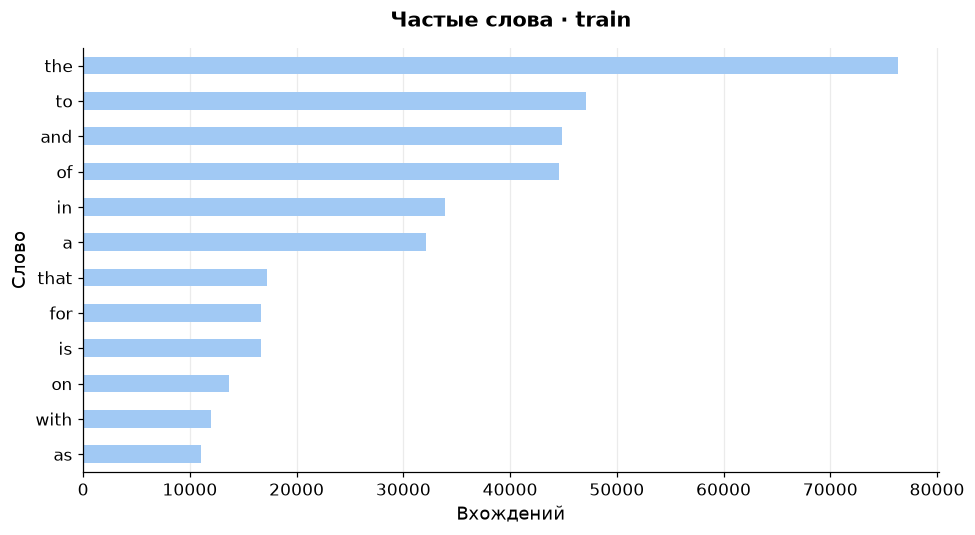

In [26]:
words = train["text"].str.split().explode()
word_counts = words.value_counts()
print("Всего слов:", len(words))
print("Разных написаний:", len(word_counts))
display(word_counts.head(10))

fig, ax = plt.subplots()
word_counts.head(12).sort_values().plot.barh(color=PALETTE[0], ax=ax)
ax.set(xlabel="Вхождений", ylabel="Слово", title="Частые слова · train")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

1 764 183 слова, 148 822 разных написания. В частотах преобладают `the`, `to`, `and`, `of`.

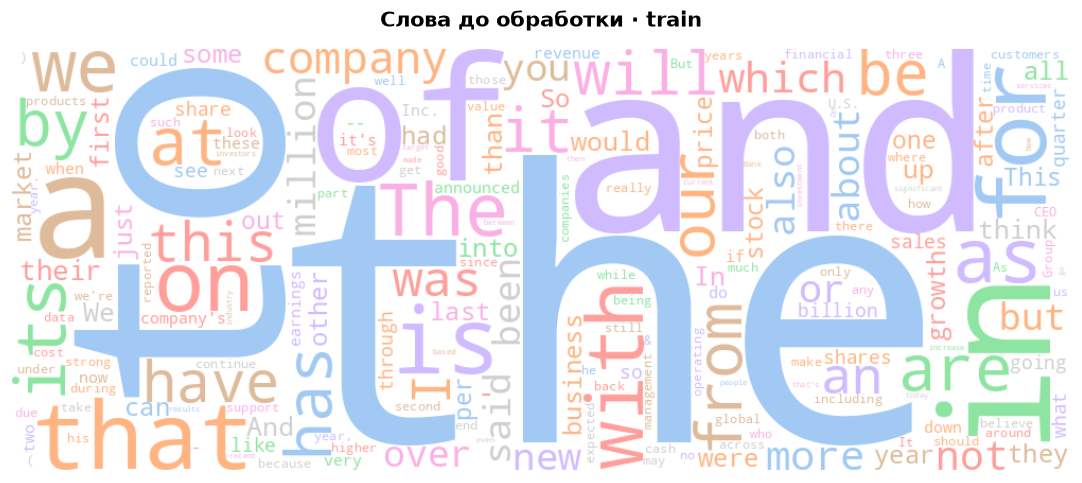

In [27]:
from wordcloud import WordCloud
from matplotlib.colors import ListedColormap

cloud = WordCloud(width=1000, height=400, background_color="white", random_state=42,
                  colormap=ListedColormap(PALETTE))
cloud.generate_from_frequencies(word_counts.to_dict())
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.imshow(cloud, interpolation="bilinear")
ax.set_title("Слова до обработки · train")
ax.axis("off")
plt.tight_layout()
plt.show()

Регистр, числа и прикреплённые знаки увеличивают число разных написаний. Нормализация позволит объединить варианты одного слова и сократить словарь.

## 8. Стоп-слова и лемматизация

In [28]:
token_pattern = r"[a-z][a-z0-9]*(?:[&'-][a-z0-9]+)*"
tokens = train["text"].str.lower().str.findall(token_pattern)
tokens.head(3)

0                                                                                                                                                    [twtr, twitter]
1    [yeah, i'd, be, happy, to, so, first, just, on, the, share, repurchase, i, will, just, echo, what, you, said, don't, read, anything, into, that, i, would, s...
2    [you, know, alexia, it, s, a, little, early, for, us, to, comment, on, the, cost, side, for, next, year, we, are, literally, just, beginning, to, look, at, ...
Name: text, dtype: object

Токены начинаются с латинской буквы. Регистр приведён к нижнему.

### Стоп-слова

In [29]:
import nltk
from nltk.corpus import stopwords

nltk.download("stopwords", quiet=True, raise_on_error=True)
keep = {"no", "not", "nor", "never", "without", "against", "down", "up", "off", "over", "under"}
stop_words = set(stopwords.words("english")) - keep
stop_words = {word for word in stop_words if not word.endswith("n't")}

no_stop = []
for text_words in tokens:
    filtered = []
    for word in text_words:
        if word not in stop_words:
            filtered.append(word)
    no_stop.append(filtered)
no_stop = pd.Series(no_stop, index=train.index)
no_stop.head(3)

0                                                                                                                                                    [twtr, twitter]
1    [yeah, happy, first, share, repurchase, echo, said, don't, read, anything, would, say, year, taken, little, bit, cautious, approach, liquidity, general, goi...
2    [know, alexia, little, early, us, comment, cost, side, next, year, literally, beginning, look, budgets, bubbling, up, local, units, tell, lot, depend, reven...
dtype: object

Стоп-слова удалены, отрицания сохранены.

### WordNet: существительные

In [30]:
from nltk.stem import WordNetLemmatizer

nltk.download("wordnet", quiet=True, raise_on_error=True)
lemmatizer = WordNetLemmatizer()

lemmas = []
for text_words in no_stop:
    result = []
    for word in text_words:
        result.append(lemmatizer.lemmatize(word, pos="n"))
    lemmas.append(result)
lemmas = pd.Series(lemmas, index=train.index)

lemma_examples = pd.DataFrame({"Слово": ["shares", "companies", "us", "https"]})
lemma_examples["Лемма"] = lemma_examples["Слово"].apply(lemmatizer.lemmatize)
display(lemma_examples)

,Слово,Лемма
0,shares,share
1,companies,company
2,us,u
3,https,http


WordNet объединяет формы существительных. `us` превращается в `u`, `https` - в `http`.

### Изменение статистик

In [31]:
def text_stats(texts):
    all_words = texts.explode().dropna()
    return {
        "Вхождений": len(all_words),
        "Словарь": all_words.nunique(),
        "Средняя длина": texts.str.len().mean(),
        "Пустых текстов": texts.str.len().eq(0).sum(),
    }

comparison = pd.DataFrame({
    "Токены": text_stats(tokens),
    "Без стоп-слов": text_stats(no_stop),
    "После лемматизации": text_stats(lemmas),
}).T
display(comparison.round(2))

display(train.loc[no_stop.str.len().eq(0), ["text", "label", "source"]])

,Вхождений,Словарь,Средняя длина,Пустых текстов
Токены,1722614.0,69459.0,49.79,0.0
Без стоп-слов,1060942.0,69294.0,30.67,1.0
После лемматизации,1060942.0,65230.0,30.67,1.0


,text,label,source
5793,Re $T re$$,NEUTRAL,timkoornstra_tweets


После токенизации - 1 722 614 вхождений, словарь 69 459. Стоп-слова сокращают число вхождений до 1 060 942, среднюю длину - с 49,79 до 30,67. Текст `Re $T re$$` становится пустым: в нём теряются тикер и короткие слова.

Лемматизация уменьшает словарь с 69 294 до 65 230 (-5,9%). Варианты со стоп-словами и лемматизацией сравним на validation.

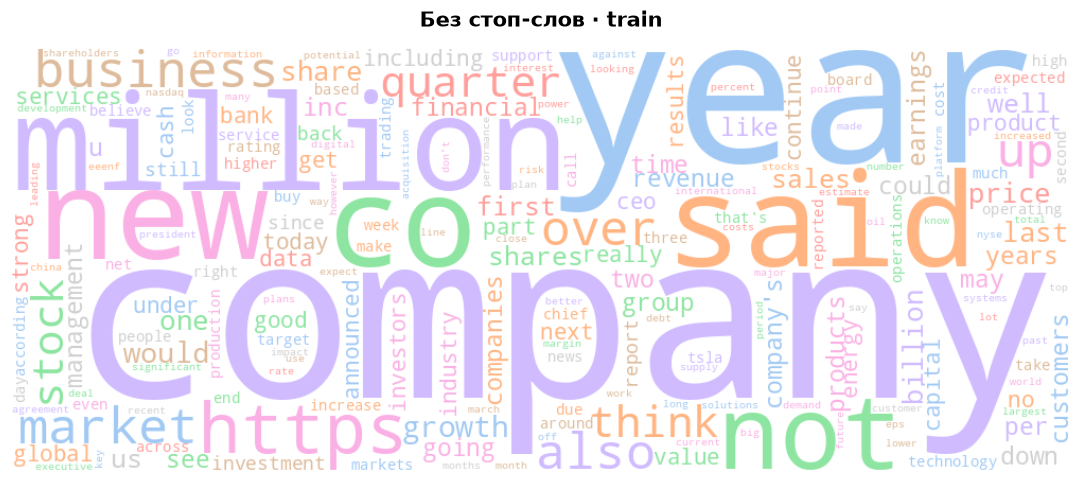

In [32]:
no_stop_counts = no_stop.explode().value_counts()
cloud = WordCloud(width=1000, height=400, background_color="white", random_state=42,
                  colormap=ListedColormap(PALETTE))
cloud.generate_from_frequencies(no_stop_counts.to_dict())
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.imshow(cloud, interpolation="bilinear")
ax.set_title("Без стоп-слов · train")
ax.axis("off")
plt.tight_layout()
plt.show()

Частые слова: `company`, `year`, `million`, `business`. `co` и `https` приходят из ссылок.

## 9. Слова и тональность

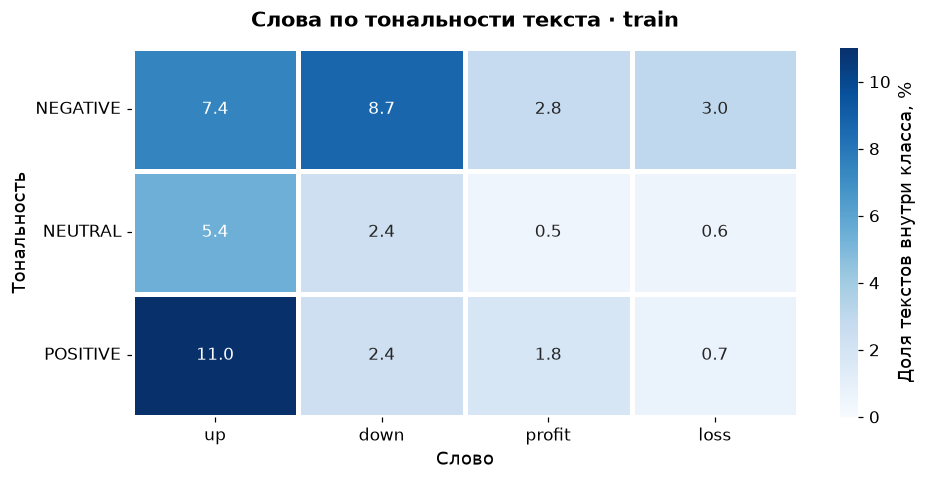

In [33]:
word_presence = pd.DataFrame(index=train.index)
for word in ["up", "down", "profit", "loss"]:
    contains_word = []
    for text_words in tokens:
        contains_word.append(word in text_words)
    word_presence[word] = contains_word
word_shares = word_presence.groupby(train["label"]).mean() * 100
word_shares = word_shares.reindex(LABELS)

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.heatmap(word_shares, annot=True, fmt=".1f", cmap="Blues", vmin=0, linewidths=2,
            ax=ax, cbar_kws={"label": "Доля текстов внутри класса, %"})
ax.set(title="Слова по тональности текста · train", xlabel="Слово", ylabel="Тональность")
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
ax.grid(False)
plt.tight_layout()
plt.show()

`up` встречается в 11,0% положительных текстов train, `down` - в 8,7% отрицательных. `profit` чаще встречается в отрицательном классе (2,8%), чем в положительном (1,8%). Для baseline сравним TF-IDF с униграммами и биграммами, чтобы учесть соседние слова и отрицания.

## Итог

- Берём `text` как вход и `label` как целевую метку. Распределения изучены на train. Варианты обработки сравним на validation, итоговую модель оценим на test.
- Пропусков и точных дублей нет. После нормализации найдено 4 группы совпадений. По косинусной близости найдено 5 пар, в двух из них различаются смысл и метки. Перед обучением проверим похожие тексты, которые попали в train и test.
- Новости и твиты составляют 69,4% обучающей выборки. Помимо общей macro-F1, посмотрим качество по классам и источникам.
- Нейтральные тексты короче во всех источниках. Длину проверим как дополнительный признак. Обрезка сильнее затрагивает стенограммы.
- При подготовке текста обработаем HTML-коды и ссылки, сохраним числа, тикеры и отрицания. После очистки проверим пустые строки.
- Для baseline сравним TF-IDF с униграммами и биграммами. Лемматизацию проверим отдельно из-за изменений сокращений.